## 3_RF_city_city notebook
This notebooks allows to 
* import footprints and train/test datasets of the 6 swiss cities, define `train_city`
* import embeddings and
* train a Random Forest classifier on 2022 embeddings with `train_city`dataset (NB: default hyperparameters are obtained by optimization procedure, see  nb `2_RF_opti`, but they can be modified.)
* get predictive performance of the RF by testing it on `test_city`
* more tests/plots etc.
  
This notebook is a "playground" to quickly test a scenario, produce plots etc.


In [3]:
import geemap
import ee

#ee.Authenticate(force=True)
ee.Initialize(project='ee-sbouchiba')


### **Import input data**

In [9]:
## Import Geneva footprint
import geopandas as gpd
import json

city_names = ['basel', 'bern', 'geneva', 'lausanne', 'lugano', 'zurich']
train_city = 'allcity'


allcity_roi_path = './input/footprints/study_areas.geojson'
allcity_roi_gpd = gpd.read_file(allcity_roi_path)
allcity_roi_gpd = allcity_roi_gpd.to_crs("EPSG:4326") # convert projected CRS into WGS84 longitude/latitude.

geom = {
    "geneva":   allcity_roi_gpd.geometry.iloc[0],
    "lausanne": allcity_roi_gpd.geometry.iloc[1],
    "bern":     allcity_roi_gpd.geometry.iloc[2],
    "basel":    allcity_roi_gpd.geometry.iloc[3],
    "zurich":   allcity_roi_gpd.geometry.iloc[4],
    "lugano":   allcity_roi_gpd.geometry.iloc[5],
    "allcity":  allcity_roi_gpd.union_all(),
}

roi = ee.Geometry(geom['allcity'].__geo_interface__)
roi_fc = ee.FeatureCollection([ee.Feature(roi)])


In [4]:
## Import train/test datasets

#train_polygons = ee.FeatureCollection('./input/geneva_2022_training_polygons.geojson');
#test_polygons  = ee.FeatureCollection('./input/geneva_2022_testing_polygons.geojson');
import geopandas as gpd
import pandas as pd

train_city = 'zurich'

## Collect training samples
if train_city=='allcity':
    centroid_gdfs = []
    polygon_gdfs  = []
    for city in city_names:
        # The paths are original samples taken from Moix2024
        centroid_gdf = gpd.read_file(
            f"./input/samples/original/{city}_2022_training_centroids.geojson"
        )
        polygon_gdf = gpd.read_file(
            f"./input/samples/original/{city}_2022_training_polygons.geojson"
        )
    
        # Optional: keep track of origin city
        centroid_gdf["city"] = city
        polygon_gdf["city"] = city
    
        centroid_gdfs.append(centroid_gdf)
        polygon_gdfs.append(polygon_gdf)
    
    # Merge all cities
    train_centroids_gdf = gpd.GeoDataFrame(
        pd.concat(centroid_gdfs, ignore_index=True),
        crs=centroid_gdfs[0].crs
    )
    
    train_polygons_gdf = gpd.GeoDataFrame(
        pd.concat(polygon_gdfs, ignore_index=True),
        crs=polygon_gdfs[0].crs
    )

else:
    train_centroids_gdf = gpd.read_file(f'./input/samples/original/{train_city}_2022_training_centroids.geojson')
    train_polygons_gdf = gpd.read_file(f'./input/samples/original/{train_city}_2022_training_polygons.geojson')
    train_centroids_gdf['city'] = train_city
    train_polygons_gdf['city'] = train_city

#print(train_centroids_gdf.columns)

# Remove signature class for test datasets
train_centroids_gdf = (train_centroids_gdf[train_centroids_gdf["macroclass_id"] != 1].copy())
train_polygons_gdf = (train_polygons_gdf[train_polygons_gdf["macroclass_id"] != 1].copy())

# Re-map: define new class mapping that is simpler to handle
class_mapping = {
    2: 1,   # Compact MR
    5: 2,   # Open MR
    6: 3,   # Open LR
    8: 4,   # Large LR
    11: 5,  # Dense Trees
    14: 6,  # Low plants
    15: 7,  # Bare Rock/Paved
    17: 8   # Water
}

# Some data re-arrangement
train_centroids_gdf["LCZ_class"] = (train_centroids_gdf["macroclass_id"].map(class_mapping))
train_polygons_gdf["LCZ_class"]  = (train_polygons_gdf["macroclass_id"].map(class_mapping))
# Some monitoring
#print(train_centroids_gdf.columns.tolist())
#print(train_centroids_gdf["LCZ_class"].value_counts().sort_index())
#print(test_centroids_gdf["LCZ_class"].value_counts().sort_index())
#print(train_centroids_gdf.shape)
#print(test_centroids_gdf.shape)

# Convert to EE datasets
train_centroids = geemap.geopandas_to_ee(train_centroids_gdf)
train_polygons  = geemap.geopandas_to_ee(train_polygons_gdf)


In [5]:

test_city = 'zurich'

test_centroids_gdf = gpd.read_file(f"./input/samples/original/{test_city}_2022_testing_centroids.geojson")
test_polygons_gdf = gpd.read_file(f"./input/samples/original/{test_city}_2022_testing_polygons.geojson")

test_centroids_gdf["LCZ_class"]  = (test_centroids_gdf["macroclass"].map(class_mapping))
test_polygons_gdf["LCZ_class"]   = (test_polygons_gdf["macroclass"].map(class_mapping))

test_centroids  = geemap.geopandas_to_ee(test_centroids_gdf)
test_polygons   = geemap.geopandas_to_ee(test_polygons_gdf)

# define point_id
test_centroids = test_centroids.map(lambda f: f.set('point_id', f.get('system:index')))

In [6]:
print(len(train_centroids_gdf))
print(len(test_centroids_gdf))

360
155


In [12]:
## Sanity check: polygons, centroids, Geneva footprint

palette = [
    "#7A2A12",  # Compact MR
    "#DE6321",  # Open MR
    "#EAC89E",  # Open LR
    "#CFC9AE",  # Large LR
    "#5A772C",  # Dense Trees
    "#A2C766",  # Low plants
    "#4A442B",  # Bare Rock/Paved
    "#89C9E8"   # Water
]

# Define style
def style_polygon(feature):
    cls = ee.Number(feature.get("LCZ_class")).subtract(1).toInt()
    color = ee.List(palette).get(cls)
    return feature.set({
        "style": {
            "color": color,
            "fillColor": color,
            "width": 1
        }
    })
def style_centroid(feature):
   
    cls = ee.Number(feature.get("LCZ_class")).subtract(1).toInt()
    color = ee.List(palette).get(cls)
    return feature.set({
        "style": {
            "color": 'black',
            "fillColor": color,
            "width": 1
        }
    })


train_centroids_fc = ee.FeatureCollection(train_centroids).map(style_centroid)
train_polygons_fc  = ee.FeatureCollection(train_polygons).map(style_polygon)

styled_train_polygons = train_polygons_fc.style(**{"styleProperty": "style"})
styled_train_centroids = train_centroids_fc.style(**{"styleProperty": "style"})




# Add ROI layer
roi_style = {
    'color': 'black',
    'fillColor': '00000000',
    'width': 2
}

## Draw map with ROI, polygons, centroids
Map = geemap.Map()
Map.centerObject(roi, 10)


Map.addLayer(roi_fc.style(**roi_style), {}, 'ROI')
Map.addLayer(styled_train_polygons, {},  "Train Polygons")
Map.addLayer(styled_train_centroids, {}, "Train Centroids")
#Map.addLayer(styled_test_polygons, {},   "Test Polygons")
#Map.addLayer(styled_test_centroids, {}, "Test Centroids")

Map.addLayerControl()
#Map



Map(center=[46.76520016697394, 7.484694823649335], controls=(WidgetControl(options=['position', 'transparent_b…

In [ ]:
## Print full map + ROIs

In [11]:
# Import embeddings
year = 2022;
startDate = ee.Date.fromYMD(year, 1, 1);
endDate = startDate.advance(1, 'year');

embeddings = ee.ImageCollection('GOOGLE/SATELLITE_EMBEDDING/V1/ANNUAL');
embeddingsFiltered = embeddings\
  .filter(ee.Filter.date(startDate, endDate))\
  .filter(ee.Filter.bounds(roi));

embeddingsImage = embeddingsFiltered.mosaic();

#Overlay the samples on the image to get training data.
#
training = embeddingsImage.sampleRegions(collection = train_centroids, properties=['LCZ_class'], scale=10)
#training = embeddingsImage.sampleRegions(collection = train_polygons, properties=['LCZ_class'], scale=10)

### Train a classifier

In [13]:
# Used best Random Forest (optimised on Geneva -> Geneva)
numberOfTrees = 500
variablesPerSplit = 8
minLeafPopulation = 5

#classifier = ee.Classifier.smileGradientTreeBoost(n_trees).train(
classifier = ee.Classifier.smileRandomForest(numberOfTrees=numberOfTrees,
                                                         variablesPerSplit = variablesPerSplit,
                                                         minLeafPopulation = minLeafPopulation).\
                                        train(features=training, 
                                        classProperty='LCZ_class', 
                                        inputProperties=embeddingsImage.bandNames())

# Classify the input imagery.
classified = embeddingsImage.classify(classifier)

# Get a confusion matrix representing resubstitution accuracy.
#train_accuracy = classifier.confusionMatrix()
#display('Resubstitution error matrix:', train_accuracy)
#display('Training overall accuracy:', train_accuracy.accuracy())

### Validation

In [14]:
# Sample the classified map at the test points.
# i.e. create a FeatureCollection containing:
# LCZ_class     = reference class
# classification = predicted class 
import numpy as np
import pandas as pd

test_city = 'lausanne'

test_centroids_gdf = gpd.read_file(f"./input/samples/{test_city}_2022_testing_centroids.geojson")
test_polygons_gdf = gpd.read_file(f"./input/samples/{test_city}_2022_testing_polygons.geojson")

test_centroids_gdf["LCZ_class"]  = (test_centroids_gdf["macroclass"].map(class_mapping))
test_polygons_gdf["LCZ_class"]   = (test_polygons_gdf["macroclass"].map(class_mapping))

test_centroids  = geemap.geopandas_to_ee(test_centroids_gdf)
test_polygons   = geemap.geopandas_to_ee(test_polygons_gdf)

# define point_id
test_centroids = test_centroids.map(lambda f: f.set('point_id', f.get('system:index')))

validation = classified.sampleRegions(
    collection=test_centroids,
    #collection=test_polygons,
    properties=['LCZ_class', 'point_id'],
    scale=10,
    geometries=True
)

print(validation.first().getInfo())

{'type': 'Feature', 'geometry': {'geodesic': False, 'type': 'Point', 'coordinates': [6.5675381264336155, 46.5100492564672]}, 'id': '0_0', 'properties': {'LCZ_class': 8, 'classification': 8, 'point_id': '0'}}


In [15]:
## Compute validation metrics and save in Excel file
# Get confusion matrix:

labels = [
    "Compact MR",
    "Open MR",
    "Open LR",
    "Large LR",
    "Dense Trees",
    "Low Plants",
    "Bare/Paved",
    "Water"
]


confusion_matrix = validation.errorMatrix(
    'LCZ_class',
    'classification'
)
cm = np.array(confusion_matrix.getInfo())
# EE internally allocates first row and first column of zeroes for some reason -> remove them
cm = cm[1:, 1:]

diag = np.diag(cm)
PA = 100 * diag / cm.sum(axis=1)
UA = 100 * diag / cm.sum(axis=0)
OA = 100 * diag.sum() / cm.sum()

# Convert to pandas dataframe
df = pd.DataFrame(cm,index=labels,columns=labels)

df["PA (%)"] = np.round(PA, 1)

ua_row = list(np.round(UA, 1))
ua_row.append(np.round(OA, 1))
df.loc["UA (%)"] = ua_row

import openpyxl
df.to_excel(f"./tables/CM_{train_city}_{test_city}_RF_{numberOfTrees}_{variablesPerSplit}_{minLeafPopulation}.xlsx")

### **Misclassification analysis**

#### **Misclassified points on a Map**

In [16]:
import folium
import geopandas as gpd
from shapely.geometry import Point
import matplotlib.pyplot as plt


class_labels = {1:'Compact MR', 2:'Open MR', 3:'Open LR', 4:'Large LR',
                5:'Dense Trees', 6:'Low plants', 7:'Bare/Paved', 8:'Water'}

# --- Pull misclassified points locally ---
# Re-run validation with geometries=True if not done yet

misclassified = validation.filter(ee.Filter.notEquals(leftField='classification',rightField='LCZ_class'))
misclassified_local = misclassified.getInfo()  # misclassified = validation.filter(neq)

rows = []
for idx, f in enumerate(misclassified_local['features']):
    props = f['properties']
    coords = f['geometry']['coordinates']
    rows.append({
        'id': props['point_id'],
        'lon': coords[0],
        'lat': coords[1],
        'true_class':      class_labels[int(props['LCZ_class'])],
        'predicted_class': class_labels[int(props['classification'])],
        'confusion':       f"{class_labels[int(props['LCZ_class'])]} → {class_labels[int(props['classification'])]}"
    })

df_mis = pd.DataFrame(rows)

# --- Color by confusion pair ---
# Assign a color per unique confusion pair for visual grouping
unique_pairs = df_mis['confusion'].unique()
cmap = plt.cm.get_cmap('tab20', len(unique_pairs))
pair_colors = {pair: '#{:02x}{:02x}{:02x}'.format(
                    int(cmap(i)[0]*255), int(cmap(i)[1]*255), int(cmap(i)[2]*255))
               for i, pair in enumerate(unique_pairs)}

# --- Build folium map ---
center = [df_mis['lat'].mean(), df_mis['lon'].mean()]
#m = folium.Map(location=center, zoom_start=13, tiles='CartoDB positron')
m = folium.Map(location=center, zoom_start=13, tiles=None)

folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Esri",
    name="Satellite",
    opacity=0.7
).add_to(m)

# Optional: add the classified raster as a tile layer via GEE
# (requires geemap's get_tile_layer_url)
map_id = classified.getMapId({'min':1,'max':8,'palette':palette})


# --- Add training polygons (semi-transparent, colored by LCZ class) ---
# Use same palette as classification
class_palette = {1:'#8B0000', 2:'#FF4500', 3:'#FFA500', 4:'#FFD700',
                 5:'#228B22', 6:'#90EE90', 7:'#A9A9A9', 8:'#1E90FF'}

train_poly_layer = folium.FeatureGroup(name='Training polygons', show=True)

for _, row in train_polygons_gdf.iterrows():
    lcz = int(row['LCZ_class'])
    color = class_palette.get(lcz, '#888888')
    
    folium.GeoJson(
        row['geometry'].__geo_interface__,
        style_function=lambda f, c=color: {
            'fillColor': c,
            'color':     c,
            'weight':    1,
            'fillOpacity': 0.25,
            'opacity':     0.6
        },
        tooltip=folium.Tooltip(
            f"<b>Training polygon</b><br>"
            f"Class: {class_labels[lcz]}<br>"
            f"City: {row.get('city', '?')}",
            sticky=True
        )
    ).add_to(train_poly_layer)

train_poly_layer.add_to(m)

# --- Add misclassified points with tooltips ---
for _, row in df_mis.iterrows():
    # Point marker
    folium.CircleMarker(
        location=[row['lat'], row['lon']],
        radius=6,
        color=pair_colors[row['confusion']],
        fill=True,
        fill_opacity=0.85,
        tooltip=folium.Tooltip(
            f"<b>ID:</b> {row['id']}<br>"
            f"<b>True:</b> {row['true_class']}<br>"
            f"<b>Predicted:</b> {row['predicted_class']}",
            sticky=True
        )
    ).add_to(m)

    # Visible ID label
    folium.map.Marker(
        [row['lat'], row['lon']],
        icon=folium.DivIcon(
            icon_size=(20, 20),
            icon_anchor=(-6, 6),  # offsets label so it doesn't overlap the marker
            html=f'<div style="font-size:10px;color:black;font-weight:bold;'
                 f'text-shadow:1px 1px 1px white;">{row["id"]}</div>'
        )
    ).add_to(m)

# --- Legend for confusion pairs ---
legend_html = "<div style='position:fixed;bottom:30px;left:30px;z-index:1000;" \
              "background:white;padding:10px;border-radius:6px;font-size:12px;'>"
legend_html += "<b>Confusion pairs</b><br>"
for pair, color in pair_colors.items():
    legend_html += f"<span style='color:{color}'>●</span> {pair}<br>"
legend_html += "</div>"
m.get_root().html.add_child(folium.Element(legend_html))

folium.LayerControl().add_to(m)

# Display in notebook
from folium.plugins import Fullscreen

Fullscreen(
    position="topright",
    title="Full Screen",
    title_cancel="Exit Full Screen",
    force_separate_button=True,
).add_to(m)
m

#### **Embedding-space distance for misclassified points**

Plotting A07 vs A39 for classes: {np.int64(1): 'Compact MR', np.int64(2): 'Open MR', np.int64(3): 'Open LR', np.int64(4): 'Large LR', np.int64(5): 'Dense Trees', np.int64(6): 'Low plants', np.int64(7): 'Bare/Paved', np.int64(8): 'Water'}
Misclassified test points: 33 / 160


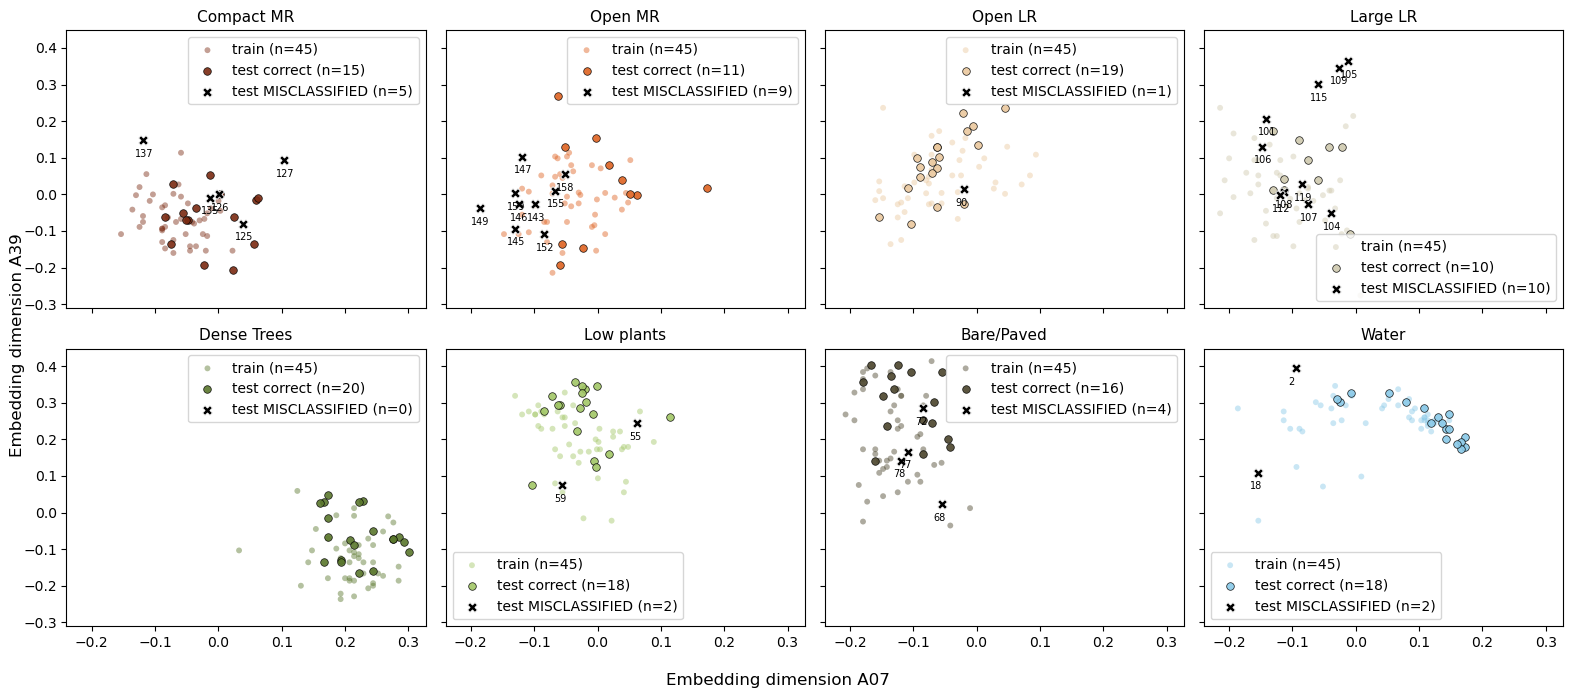

Saved: embedding_scatter_by_class.png, embedding_scatter_overlay.png


In [19]:
"""
Diagnostic: 2D scatter of training + test points in embedding space
=====================================================================

Plots training and test points along TWO chosen embedding dimensions
(e.g. your two most important features from RF feature importance), one
subplot per LCZ class, so you can visually inspect what each class's "blob"
actually looks like: tight and compact vs. spread out vs. possibly
multimodal (two separate sub-clusters).

Train points = light class-colored dots.
Test points, correctly classified   = colored 'o' with black outline.
Test points, MISCLASSIFIED          = solid BLACK 'X', larger, so errors
                                       stand out visually against the blob.

CAVEAT: this is a 2D slice through a 64-dimensional space. Two classes (or
sub-clusters within a class) can look separated here but be entangled in
the other 62 dimensions, or vice versa. Treat this as a sanity-check /
intuition-builder -- for a rigorous, full-dimensional check, see script 06
(multimodality check via k-means).

Uses your existing objects:
- embeddingsImage : ee.Image, 64-band Alpha Earth embedding
- train_centroids  : ee.FeatureCollection, training points, property 'LCZ_class'
- test_centroids   : ee.FeatureCollection, test points, property 'LCZ_class'
- classified       : ee.Image, the classifier's output (predicted class per pixel)
- class_labels     : dict mapping class id -> readable name
- palette          : list of hex colors, in the same order as class_labels
"""

import ee
import geemap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from adjustText import adjust_text

LABEL_PROP = "LCZ_class"
PRED_PROP = "classification"

# EDIT: swap these for your actual most-important bands from feature importance
FEATURE_X = "A07"
FEATURE_Y = "A39"

class_ids_sorted = sorted(class_labels.keys())
class_colors = {cid: palette[i] for i, cid in enumerate(class_ids_sorted)}

# 1. Sample the two chosen bands at train points, and the two bands + predicted
#    class at test points, so we can tell correct from misclassified.
two_band_image = embeddingsImage.select([FEATURE_X, FEATURE_Y])
two_band_with_pred = two_band_image.addBands(classified.rename(PRED_PROP))

train_sample = two_band_image.sampleRegions(
    collection=train_centroids, properties=[LABEL_PROP, 'point_id'], scale=10, geometries=False
)
'''
test_sample = two_band_with_pred.sampleRegions(
    collection=test_centroids, properties=[LABEL_PROP], scale=10, geometries=False
)
'''
test_sample = two_band_with_pred.sampleRegions(
    collection=test_centroids, properties=[LABEL_PROP, 'point_id'], scale=10, geometries=False
)

train_df = geemap.ee_to_df(train_sample, remove_geom=False)
if "geo" in train_df.columns:
    train_df = train_df.drop(columns=["geo"])
test_df = geemap.ee_to_df(test_sample, remove_geom=False)
if "geo" in test_df.columns:
    test_df = test_df.drop(columns=["geo"])

test_df["is_misclassified"] = test_df[PRED_PROP] != test_df[LABEL_PROP]

class_values = sorted(train_df[LABEL_PROP].unique())
n_mis_total = int(test_df["is_misclassified"].sum())
print(f"Plotting {FEATURE_X} vs {FEATURE_Y} for classes:",
      {cv: class_labels.get(cv, cv) for cv in class_values})
print(f"Misclassified test points: {n_mis_total} / {len(test_df)}")
# 2. Grid of subplots, one per class
n = len(class_values)
ncols = 4
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols,  sharex=True, sharey=True, figsize=(4 * ncols, 3.5 * nrows))
axes = np.array(axes).reshape(-1)

x_all = pd.concat([train_df[FEATURE_X], test_df[FEATURE_X]])
y_all = pd.concat([train_df[FEATURE_Y], test_df[FEATURE_Y]])
pad_x = (x_all.max() - x_all.min()) * 0.05
pad_y = (y_all.max() - y_all.min()) * 0.05
xlim = (x_all.min() - pad_x, x_all.max() + pad_x)
ylim = (y_all.min() - pad_y, y_all.max() + pad_y)


for i, cv in enumerate(class_values):
    ax = axes[i]
    color = class_colors[cv]

    tr = train_df[train_df[LABEL_PROP] == cv]
    te = test_df[test_df[LABEL_PROP] == cv]
    te_correct = te[~te["is_misclassified"]]
    te_mis = te[te["is_misclassified"]]

    ax.scatter(tr[FEATURE_X], tr[FEATURE_Y], c=color, s=18, alpha=0.45,
               edgecolor="none", label=f"train (n={len(tr)})", zorder=1)
    ax.scatter(te_correct[FEATURE_X], te_correct[FEATURE_Y], facecolor=color, edgecolor="black",
               marker="o", s=30, linewidth=0.5, alpha=0.9,
               label=f"test correct (n={len(te_correct)})", zorder=2)
    ax.scatter(te_mis[FEATURE_X], te_mis[FEATURE_Y], facecolor="black", edgecolor="white",
               marker="X", s=50, linewidth=0.6,
               label=f"test MISCLASSIFIED (n={len(te_mis)})", zorder=3)

    
    texts = []
    for _, r in te_mis.iterrows():
        text = ax.annotate(str(int(r['point_id'])), (r[FEATURE_X], r[FEATURE_Y]),
                            fontsize=7, xytext=(-6, -12), textcoords='offset points')
        texts.append(text)
    '''
    if texts:  # adjust_text errors/no-ops on an empty list for some versions
        adjust_text(
            texts,
            ax=ax,
            prevent_crossings=True,
            force_text=(0.3, 0.5),
            arrowprops=dict(arrowstyle="-", color="dimgray", lw=0.6, alpha=0.8,
                             shrinkA=0, shrinkB=2),
        )
    '''
        
    if len(tr) > 0:
        ax.scatter(tr[FEATURE_X].mean(), tr[FEATURE_Y].mean(), c="none", edgecolor="black",
                   marker="+", s=80, linewidth=1, zorder=4)

    ax.set_title(class_labels.get(cv, cv), fontsize=11)
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.legend(fontsize=10, loc="best")

    




for j in range(n, len(axes)):
    axes[j].axis("off")

fig.supxlabel(f"Embedding dimension {FEATURE_X}")
fig.supylabel(f"Embedding dimension {FEATURE_Y}")
#fig.suptitle(f"Train / test points per class, in {FEATURE_X}-{FEATURE_Y} space\n"
#             "black X = misclassified test point, black + = training centroid", y=1.02)
plt.tight_layout()
plt.savefig("./images/embedding_scatter_by_class_RFopti1_Gen_Laus.png", dpi=400, bbox_inches="tight", transparent=True)
plt.show()


print("Saved: embedding_scatter_by_class.png, embedding_scatter_overlay.png")


In [20]:
"""
Misclassification analysis (4): Embedding-space distance for misclassified points
====================================================================================

For each VALIDATION point (both correct and misclassified), compare its
distance (in 64-dim Alpha Earth embedding space) to:
  (a) the centroid of its TRUE class
  (b) the centroid of its PREDICTED class

This is a *local, per-error* diagnostic -- distinct from the global class-
separability metrics you'd compute pre-training (e.g. Jeffries-Matusita
distance between whole class distributions). Here we're asking, for each
individual mistake: "was this a reasonable confusion given where the point
sits in embedding space, or did the model do something the raw features
don't obviously explain?"

CAVEAT ON THE CENTROID ITSELF: a single mean vector per class assumes each
class is roughly a single, compact blob in embedding space. That may not
hold for classes with high intra-class variance. Alongside the centroid
distance, we also compute each class's INTRA-CLASS SPREAD (how far its own
training points typically sit from its centroid) and use it two ways:
  1. as an uncertainty bar on the plot, sized to that class's typical spread
  2. as a robust z-score, so "distance to centroid" is interpreted relative
     to how tight/loose that class normally is, not as a raw number
Note: the spread metric only tells you the MAGNITUDE of centroid unreliability,
not whether it's one diffuse blob or several separate sub-clusters -- for
that, see the scatter plots (script 05) and the multimodality check (script 06).

Uses your existing objects:
- embeddingsImage : ee.Image, 64-band Alpha Earth embedding
- train_centroids  : ee.FeatureCollection, training points, property 'LCZ_class'
- test_centroids   : ee.FeatureCollection, test points, property 'LCZ_class'
- classified       : ee.Image, the classifier's output (predicted class per pixel)
- class_labels     : dict mapping class id -> readable name, for printing/plots
- palette          : list of hex colors, in the same order as class_labels
                      (class id 1 -> palette[0], id 2 -> palette[1], etc.)
"""

import ee
import geemap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.lines as mlines

LABEL_PROP = "LCZ_class"
PRED_PROP = "classification"

class_ids_sorted = sorted(class_labels.keys())
class_colors = {cid: palette[i] for i, cid in enumerate(class_ids_sorted)}

band_names = embeddingsImage.bandNames()
band_names_list = band_names.getInfo()
print(f"{len(band_names_list)} embedding bands:", band_names_list[:5], "...")

# 1. Attach the 64 embedding bands to the Training and Testing points
training_with_bands = embeddingsImage.sampleRegions(
    collection=train_centroids, properties=[LABEL_PROP, 'point_id'], scale=10, geometries=True
)

# 2. Attach the 64 embedding bands + predicted class to ALL VALIDATION points
#    (no filtering here -- we want correct AND misclassified points)
stacked = embeddingsImage.addBands(classified.rename(PRED_PROP))
'''validation_with_bands = stacked.sampleRegions(
    collection=test_centroids, properties=[LABEL_PROP], scale=10, geometries=True
)'''
validation_with_bands = stacked.sampleRegions(
    collection=test_centroids, properties=[LABEL_PROP, 'point_id'], scale=10, geometries=True
)

# 3. Pull ALL training points to pandas, compute per-class centroids + spread
train_df = geemap.ee_to_df(training_with_bands, remove_geom=False)
if "geo" in train_df.columns:
    train_df = train_df.drop(columns=["geo"])

class_values = sorted(train_df[LABEL_PROP].unique())
print("Classes:", {cv: class_labels.get(cv, cv) for cv in class_values})

centroids = {}
intra_dists = {}  # class -> distances of that class's OWN training points to their centroid
for cv in class_values:
    subset = train_df.loc[train_df[LABEL_PROP] == cv, band_names_list].to_numpy(dtype=float)
    centroid = subset.mean(axis=0)
    centroids[cv] = centroid
    intra_dists[cv] = np.linalg.norm(subset - centroid, axis=1)

spread_stats = {}
for cv in class_values:
    d = intra_dists[cv]
    median_d = float(np.median(d))
    mad = float(np.median(np.abs(d - median_d)))
    robust_sigma = 1.4826 * mad if mad > 0 else float(np.std(d))
    spread_stats[cv] = {
        "n_train": len(d),
        "median_dist_to_centroid": median_d,
        "mean_dist_to_centroid": float(np.mean(d)),
        "robust_sigma": robust_sigma,
        "p25": float(np.percentile(d, 25)),
        "p75": float(np.percentile(d, 75)),
    }

spread_df = pd.DataFrame(spread_stats).T
spread_df.index = spread_df.index.map(lambda c: class_labels.get(c, c))
spread_df.index.name = "class"
print("\nIntra-class spread in embedding space (training points only):")
print(spread_df)

# 4. Pull ALL test/validation points to pandas
test_df = geemap.ee_to_df(validation_with_bands, remove_geom=False)
if "geo" in test_df.columns:
    test_df = test_df.drop(columns=["geo"])
test_df = test_df[band_names_list + [LABEL_PROP, PRED_PROP, "point_id"]].copy()

n_test = len(test_df)
print(f"\nTotal validation points: {n_test}")


# 5. Distances to true/predicted centroids, robust z-scores, rank of true class
#    -- computed for EVERY test point, not just misclassified ones
def compute_distances(row):
    vec = row[band_names_list].to_numpy(dtype=float)
    dists = {cv: float(np.linalg.norm(vec - cen)) for cv, cen in centroids.items()}
    true_cls = row[LABEL_PROP]
    pred_cls = row[PRED_PROP]

    ranked = sorted(dists.items(), key=lambda kv: kv[1])
    rank_of_true = [i for i, (cv, _) in enumerate(ranked, start=1) if cv == true_cls][0]

    dist_true = dists[true_cls]
    dist_pred = dists[pred_cls]
    z_true = (dist_true - spread_stats[true_cls]["median_dist_to_centroid"]) / spread_stats[true_cls]["robust_sigma"]
    z_pred = (dist_pred - spread_stats[pred_cls]["median_dist_to_centroid"]) / spread_stats[pred_cls]["robust_sigma"]

    return pd.Series(
            {
                "dist_to_true_centroid": dist_true,
                "dist_to_pred_centroid": dist_pred,
                "true_class_sigma": spread_stats[true_cls]["robust_sigma"],
                "pred_class_sigma": spread_stats[pred_cls]["robust_sigma"],
                "z_true": z_true,
                "z_pred": z_pred,
                "rank_of_true_class": rank_of_true,
            }
        )
def compute_distances_train(row):
    vec = row[band_names_list].to_numpy(dtype=float)
    dists = {cv: float(np.linalg.norm(vec - cen)) for cv, cen in centroids.items()}
    true_cls = row[LABEL_PROP]

    ranked = sorted(dists.items(), key=lambda kv: kv[1])
    rank_of_true = [i for i, (cv, _) in enumerate(ranked, start=1) if cv == true_cls][0]

    dist_true = dists[true_cls]
    z_true = (dist_true - spread_stats[true_cls]["median_dist_to_centroid"]) / spread_stats[true_cls]["robust_sigma"]

    return pd.Series(
            {
                "dist_to_true_centroid": dist_true,
                "true_class_sigma": spread_stats[true_cls]["robust_sigma"],
                "z_true": z_true,
                "rank_of_true_class": rank_of_true,
            }
        )


train_df = pd.concat([train_df, train_df.apply(compute_distances_train, axis=1)], axis=1)
test_df = pd.concat([test_df, test_df.apply(compute_distances, axis=1)], axis=1)
test_df["is_misclassified"] = test_df[PRED_PROP] != test_df[LABEL_PROP]
test_df["true_name"] = test_df[LABEL_PROP].map(class_labels)
test_df["pred_name"] = test_df[PRED_PROP].map(class_labels)
test_df["ratio_true_over_pred"] = test_df["dist_to_true_centroid"] / test_df["dist_to_pred_centroid"]

n_mis = int(test_df["is_misclassified"].sum())
print(f"Misclassified: {n_mis} / {n_test} ({100 * n_mis / n_test:.1f}%)")

df = test_df[test_df["is_misclassified"]].copy()  # kept for backward compatibility below

print(df[["true_name", "pred_name", "dist_to_true_centroid", "dist_to_pred_centroid", "LCZ_class",
          "z_true", "z_pred", "rank_of_true_class"]].describe())

surprising = df.sort_values("z_true")
print(f"\nMost surprising misclassified points (typical for their TRUE class, "
      "yet still misclassified -- sorted by z_true ascending):")
print(surprising[["true_name", "pred_name", "z_true", "z_pred", "rank_of_true_class"]].head(10))






64 embedding bands: ['A00', 'A01', 'A02', 'A03', 'A04'] ...
Classes: {np.int64(1): 'Compact MR', np.int64(2): 'Open MR', np.int64(3): 'Open LR', np.int64(4): 'Large LR', np.int64(5): 'Dense Trees', np.int64(6): 'Low plants', np.int64(7): 'Bare/Paved', np.int64(8): 'Water'}

Intra-class spread in embedding space (training points only):
             n_train  median_dist_to_centroid  mean_dist_to_centroid  \
class                                                                  
Compact MR      45.0                 0.268686               0.292002   
Open MR         45.0                 0.401397               0.415059   
Open LR         45.0                 0.436716               0.447078   
Large LR        45.0                 0.431457               0.446039   
Dense Trees     45.0                 0.402098               0.425431   
Low plants      45.0                 0.453308               0.476642   
Bare/Paved      45.0                 0.528791               0.532473   
Water          

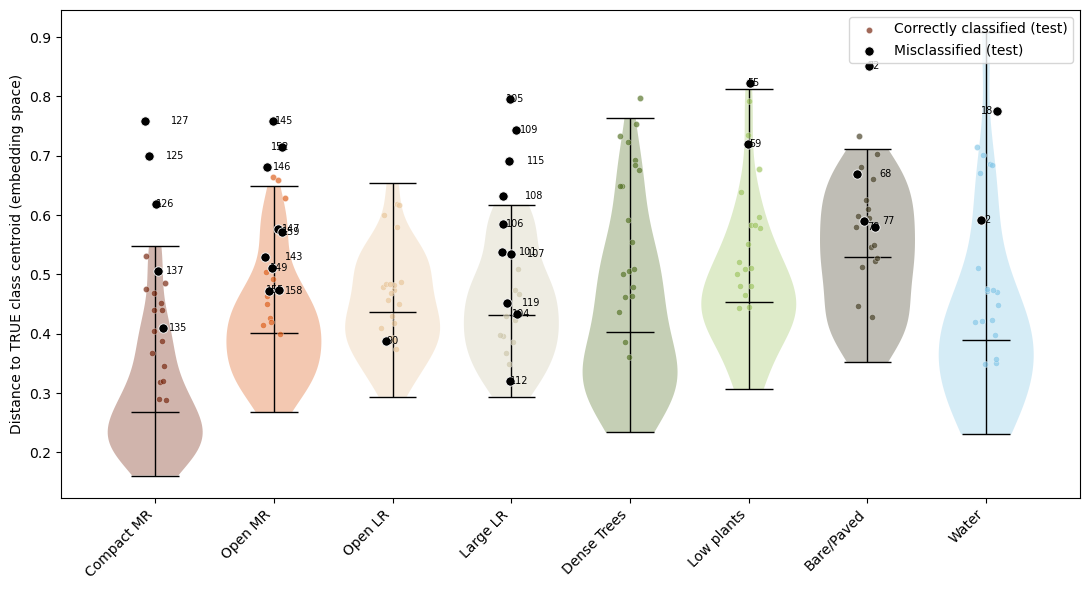

In [21]:
# 6a. Violin plot: intra-class spread (from TRAINING points), with ALL test
#     points overlaid at their true class's position -- correctly classified
#     in a light class-colored dot, misclassified in BLACK so they stand out.
present_ids = [cv for cv in class_ids_sorted if cv in class_values]
order_names = [class_labels[cv] for cv in present_ids]
order_colors = [class_colors[cv] for cv in present_ids]

fig, ax = plt.subplots(figsize=(11, 6))
violin_data = [intra_dists[cv] for cv in present_ids]
parts = ax.violinplot(violin_data, showmedians=True, widths=0.8)
for i, pc in enumerate(parts["bodies"]):
    pc.set_facecolor(order_colors[i])
    pc.set_alpha(0.35)
for key in ("cmedians", "cbars", "cmins", "cmaxes"):
    parts[key].set_color("black")
    parts[key].set_linewidth(1)

rng = np.random.default_rng(42)
for i, cv in enumerate(present_ids, start=1):
    subset = test_df[test_df[LABEL_PROP] == cv]

    correct = subset[~subset["is_misclassified"]]
    jitter_c = rng.uniform(-0.1, 0.1, size=len(correct))
    ax.scatter(np.full(len(correct), i) + jitter_c, correct["dist_to_true_centroid"],
               color=order_colors[i - 1], alpha=0.7, s=20, edgecolor="white", linewidth=0.3,
               zorder=2, label="Correctly classified (test)" if i == 1 else None)

    mis = subset[subset["is_misclassified"]]
    jitter_m = rng.uniform(-0.1, 0.1, size=len(mis))
    ax.scatter(np.full(len(mis), i) + jitter_m, mis["dist_to_true_centroid"],
               color="black", s=45, edgecolor="white", linewidth=0.6,
               zorder=3, label="Misclassified (test)" if i == 1 else None)
    for _, r in mis.iterrows():
        ax.annotate(str(int(r['point_id'])), (i + rng.uniform(-0.1, 0.1), r["dist_to_true_centroid"]),
                    fontsize=7, ha='left', va='center', xytext=(3, 0), textcoords='offset points')

ax.set_xticks(range(1, len(present_ids) + 1))
ax.set_xticklabels(order_names, rotation=45, ha="right")
ax.set_ylabel("Distance to TRUE class centroid (embedding space)")
#ax.set_title("Intra-class spread (violin, training points) vs. all validation points\n"
#              "colored dots = correctly classified, black dots = misclassified")
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig("./images/embedding_violin_intra_class_spread_RFoptiv1_Gen_Laus.png", dpi=400, transparent=True)
plt.show()


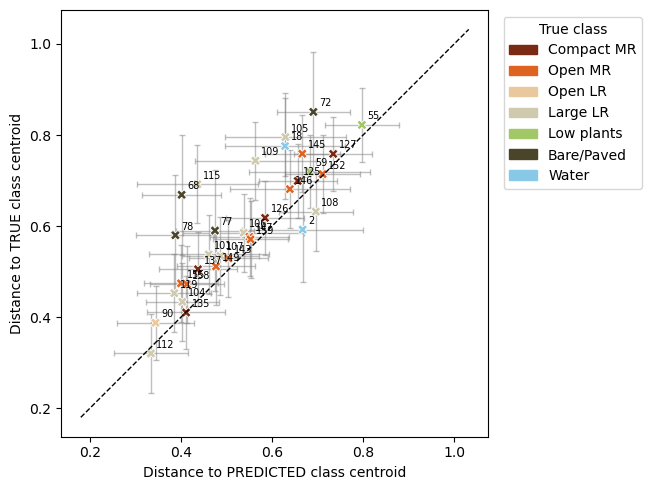

Saved: all_test_embedding_distances.csv, class_intra_class_spread.csv, embedding_intra_class_spread.png, embedding_distance_misclassified.png


In [22]:
# ===============================================================================

# 6b. Scatter: dist to true vs dist to predicted centroid, WITH uncertainty
#     bars. Only meaningful for MISCLASSIFIED points (for correct ones,
#     true==pred so this collapses to a point on the diagonal by definition).
point_colors = df[LABEL_PROP].map(class_colors)

fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(
    df["dist_to_pred_centroid"], df["dist_to_true_centroid"],
    xerr=df["pred_class_sigma"], yerr=df["true_class_sigma"],
    fmt="none", ecolor="gray", elinewidth=1, capsize=2, alpha=0.5, zorder=1,
)
ax.scatter(
    df["dist_to_pred_centroid"], df["dist_to_true_centroid"],
    facecolor=point_colors, edgecolor="white",marker="X", s=50, linewidth=0.6,
    
)
for _, r in df.iterrows():
    ax.annotate(str(int(r['point_id'])), (r['dist_to_pred_centroid'], r['dist_to_true_centroid']),
                fontsize=7, xytext=(4, 4), textcoords='offset points')
lims = [0.18, max(
    (df["dist_to_true_centroid"] + df["true_class_sigma"]).max(),
    (df["dist_to_pred_centroid"] + df["pred_class_sigma"]).max(),
) * 1.05]
ax.plot(lims, lims, "k--", lw=1, label="dist_true = dist_pred")
ax.set_xlabel("Distance to PREDICTED class centroid")
ax.set_ylabel("Distance to TRUE class centroid")
ax.set_aspect('equal')
#ax.set_title("Embedding-space distance for MISCLASSIFIED points\n"
#              "error bars = that class's own robust spread (1 sigma); "
#              "below line = point closer to its true class")

present_classes = sorted(df[LABEL_PROP].unique())
handles = [mpatches.Patch(color=class_colors[c], label=class_labels.get(c, c)) for c in present_classes]
ax.legend(handles=handles, title="True class", bbox_to_anchor=(1.02, 1), loc="best")
plt.tight_layout()
plt.savefig("./images/embedding_distance_misclassified_RFopti1_Gen_Laus.png", dpi=400, bbox_inches="tight", transparent=True)
plt.show()

test_df.to_csv("all_test_embedding_distances.csv", index=False)
spread_df.to_csv("class_intra_class_spread.csv")
print("Saved: all_test_embedding_distances.csv, class_intra_class_spread.csv, "
      "embedding_intra_class_spread.png, embedding_distance_misclassified.png")

In [23]:
"""
Diagnostic: rigorous check for multimodal (sub-clustered) classes
=====================================================================

The violin plot (script 04) tells you HOW MUCH a class's training points
spread out around their centroid, but not WHY: a wide violin could mean
(a) one genuinely diffuse blob, or (b) two or more tight sub-clusters with
an empty gap between them -- in which case the single centroid sits
somewhere no real training point actually is. The 2D scatter plots (script
05) give visual intuition but only show 2 of the 64 dimensions at a time,
so they can miss (or fabricate the appearance of) structure that's really
about other dimensions.

This script checks for sub-clustering directly in the FULL 64-dimensional
embedding space, per class, by comparing a single centroid (k=1) against a
2-centroid k-means split (k=2):

- compactness_gain_pct : how much smaller the average distance-to-nearest-
                          centroid becomes when allowing 2 centroids instead
                          of 1. Large gain (e.g. >25-30%) suggests the class
                          isn't well described by one center.
- silhouette_k2        : how well-separated the 2 sub-clusters are
                          (-1 to 1; >0.25 is a weak-but-real split, >0.5 is
                          a clear, well-separated split; near 0 or negative
                          means k=2 isn't finding real structure, it's just
                          cutting a blob in half arbitrarily).
- cluster_balance       : ratio of smaller-to-larger sub-cluster size. Very
                          low values (e.g. 0.05) mean the "split" is really
                          just isolating a handful of outliers, not a
                          genuine second population.

These are heuristic thresholds, not statistical guarantees -- treat flagged
classes as "worth a closer look" (e.g. re-run with k=3, inspect the
sub-cluster members' locations/dates, consider whether the class definition
is too broad), not as an automatic fix.

Requires: scikit-learn (pip install scikit-learn --break-system-packages if missing)

Uses your existing objects:
- embeddingsImage : ee.Image, 64-band Alpha Earth embedding
- train_centroids  : ee.FeatureCollection, training points, property 'LCZ_class'
- class_labels     : dict mapping class id -> readable name
"""

import ee
import geemap
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

LABEL_PROP = "LCZ_class"
RANDOM_STATE = 42
MIN_POINTS_FOR_CHECK = 10  # skip classes with too few points for a meaningful k=2 split

band_names = embeddingsImage.bandNames()
band_names_list = band_names.getInfo()

# 1. Pull training points with full 64-dim embedding to pandas
training_with_bands = embeddingsImage.sampleRegions(
    collection=train_centroids, properties=[LABEL_PROP], scale=10, geometries=True
)
train_df = geemap.ee_to_df(training_with_bands, remove_geom=False)
if "geo" in train_df.columns:
    train_df = train_df.drop(columns=["geo"])

class_values = sorted(train_df[LABEL_PROP].unique())

results = []
for cv in class_values:
    X = train_df.loc[train_df[LABEL_PROP] == cv, band_names_list].to_numpy(dtype=float)
    n = len(X)
    class_name = class_labels.get(cv, cv)

    if n < MIN_POINTS_FOR_CHECK:
        print(f"Skipping {class_name}: only {n} training points (< {MIN_POINTS_FOR_CHECK})")
        continue

    # k=1 baseline: single centroid, average distance to it
    centroid_k1 = X.mean(axis=0)
    dist_k1 = np.linalg.norm(X - centroid_k1, axis=1)
    mean_dist_k1 = dist_k1.mean()

    # k=2: split, average distance to each point's assigned centroid
    km = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE)
    labels_k2 = km.fit_predict(X)
    dist_k2 = np.linalg.norm(X - km.cluster_centers_[labels_k2], axis=1)
    mean_dist_k2 = dist_k2.mean()

    counts = np.bincount(labels_k2)
    cluster_balance = counts.min() / counts.max()

    sil = silhouette_score(X, labels_k2) if n >= 4 else np.nan

    compactness_gain_pct = 100 * (mean_dist_k1 - mean_dist_k2) / mean_dist_k1

    likely_multimodal = (
        (not np.isnan(sil)) and sil > 0.25
        and compactness_gain_pct > 25
        and cluster_balance > 0.1
    )

    results.append({
        "class": class_name,
        "n_train": n,
        "mean_dist_k1": round(mean_dist_k1, 4),
        "mean_dist_k2": round(mean_dist_k2, 4),
        "compactness_gain_pct": round(compactness_gain_pct, 1),
        "silhouette_k2": round(sil, 3) if not np.isnan(sil) else np.nan,
        "cluster_balance": round(cluster_balance, 3),
        "likely_multimodal": likely_multimodal,
    })
summary = pd.DataFrame(results).sort_values("silhouette_k2", ascending=False)
print("\nMultimodality check (k=1 vs k=2 split), per class:")
print(summary.to_string(index=False))

flagged = summary[summary["likely_multimodal"]]
if len(flagged) > 0:
    print(f"\n{len(flagged)} class(es) show evidence of sub-clustering -- "
          "their single centroid may be unreliable:")
    print(flagged["class"].tolist())
else:
    print("\nNo classes strongly flagged as multimodal under current thresholds.")

summary.to_csv("class_multimodality_check.csv", index=False)
print("\nSaved: class_multimodality_check.csv")

    


Multimodality check (k=1 vs k=2 split), per class:
      class  n_train  mean_dist_k1  mean_dist_k2  compactness_gain_pct  silhouette_k2  cluster_balance  likely_multimodal
      Water       45        0.4232        0.2469                  41.7          0.271            0.533               True
 Bare/Paved       45        0.5325        0.4093                  23.1          0.197            0.235              False
   Large LR       45        0.4460        0.3408                  23.6          0.181            0.188              False
 Compact MR       45        0.2920        0.2192                  24.9          0.179            0.182              False
    Open MR       45        0.4151        0.3144                  24.3          0.170            0.316              False
    Open LR       45        0.4471        0.3328                  25.6          0.169            0.533              False
Dense Trees       45        0.4254        0.3212                  24.5          0.167         

In [24]:
print("train_centroids size:", train_centroids.size().getInfo())
print("reference_points size (after exclusion):", reference_points.size().getInfo())

train_centroids size: 360
reference_points size (after exclusion): 360


### Some comparison with reference numbers

In [25]:
from pathlib import Path
import numpy as np

CITY_CODES = {
    "Geneva": "gen",
    "Lausanne": "lau",
    "Basel": "bas",
    "Bern": "ber",
    "Zurich": "zur",
    "Lugano": "lug",
}


def read_accuracy_file(filepath):

    with open(filepath, encoding="utf-8") as f:
        lines = f.readlines()

    pa = None
    ua = None
    oa = None

    for line in lines:

        if line.startswith("PA [%]"):
            pa = np.array([
                float(x)
                for x in line.strip().split(",")[1:]
                if x.strip()
            ])

        elif line.startswith("UA [%]"):
            ua = np.array([
                float(x)
                for x in line.strip().split(",")[1:]
                if x.strip()
            ])

        elif "Overall accuracy" in line:
            # extract first number appearing in the line
            import re
            oa = float(re.search(r"(\d+\.\d+)", line).group(1))

    if pa is None:
        raise ValueError(f"PA row not found in {filepath}")

    if ua is None:
        raise ValueError(f"UA row not found in {filepath}")

    if oa is None:
        raise ValueError(f"OA row not found in {filepath}")

    return {
        "PA": pa,
        "UA": ua,
        "OA": oa,
    }

In [26]:
def load_accuracy_data(root_dir):
    data = {}

    for city, code in CITY_CODES.items():

        data[city] = {}

        for sensor in ["S2", "L8"]:
            if code=='lau':
                filepath = (Path(root_dir)/city/f"Accuracy_{code}_{sensor}_2022.csv")
            else:
                filepath = (Path(root_dir)/city/f"Accuracy_{sensor}_{code}_2022.csv")

            data[city][sensor] = read_accuracy_file(filepath)

    return data

In [27]:
ROOT_DIR = '/home/bouchiba/notebooks/project/tables/LCZ_paper_2024/'
ref_data = load_accuracy_data(ROOT_DIR)

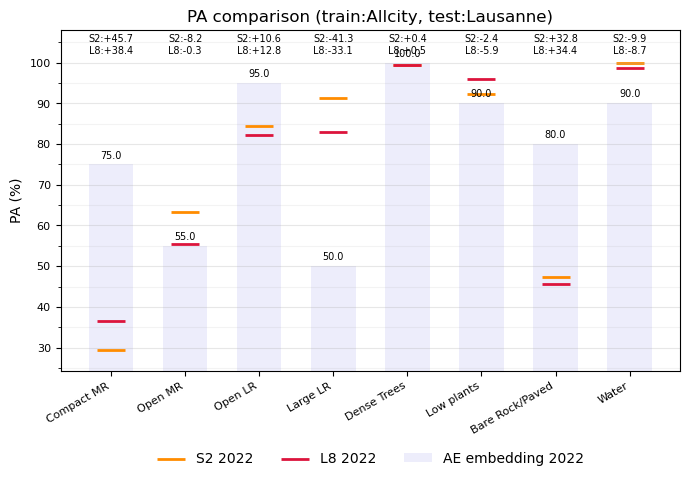

In [28]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

ref_city = test_city.capitalize()

class_names = [
    "Compact MR",
    "Open MR",
    "Open LR",
    "Large LR",
    "Dense Trees",
    "Low plants",
    "Bare Rock/Paved",
    "Water"
]

x = np.arange(len(class_names))

fig, ax = plt.subplots(figsize=(7,5))

# AE embedding bars
bars = ax.bar(
    x,
    PA,
    width=0.6,
    alpha=0.7,
    color="lavender",
    label="AE embedding 2022"
)

# S2 reference markers
ax.scatter(
    x,
    ref_data[ref_city]["S2"]["PA"],
    marker="_",
    s=400,
    linewidths=2,
    color="darkorange",
    label="S2 2022"
)

# L8 reference markers
ax.scatter(
    x,
    ref_data[ref_city]["L8"]["PA"],
    marker="_",
    s=400,
    linewidths=2,
    color="crimson",
    label="L8 2022"
)

# Labels and title
ax.set_title(
    f"PA comparison (train:{train_city.capitalize()}, test:{test_city.capitalize()})",
    fontsize=12
)

ax.set_ylabel("PA (%)", fontsize=10)
ax.set_ylim(60,105)
ax.yaxis.set_major_locator(ticker.MultipleLocator(10))
ax.yaxis.set_minor_locator(ticker.MultipleLocator(5))
ax.grid(which="major", axis="y", alpha=0.3)
ax.grid(which="minor", axis="y", alpha=0.15)

ax.set_xticks(x)
ax.set_xticklabels(
    class_names,
    rotation=30,
    ha="right",
    fontsize=8
)

ax.grid(axis="y", alpha=0.3)
ax.tick_params(axis="y", labelsize=8)

# Common y-range with padding
all_values = np.concatenate([
    PA,
    ref_data[ref_city]["S2"]["PA"],
    ref_data[ref_city]["L8"]["PA"]
])

ymin = max(0, np.min(all_values) - 5)
ymax = np.max(all_values) + 8
ax.set_ylim(ymin, ymax)

# Annotate AE values
for i, v in enumerate(PA):
    ax.text(
        i,
        v + 1,
        f"{v:.1f}",
        ha="center",
        va="bottom",
        fontsize=7
    )

# Annotate differences to references
for i, (ae, s2, l8) in enumerate(zip(
    PA,
    ref_data[ref_city]["S2"]["PA"],
    ref_data[ref_city]["L8"]["PA"]
)):
    ax.text(
        i,
        ymax - 1,
        f"S2:{ae-s2:+.1f}\nL8:{ae-l8:+.1f}",
        ha="center",
        va="top",
        fontsize=7
    )

#ax.legend(bbox_to_anchor=(1, 1), loc='upper left')

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.2),
    ncol=3,
    frameon=False
)

plt.tight_layout()

plt.savefig(
    f"./images/comparison_PA_{train_city}_{test_city}_RF_"
    f"{numberOfTrees}_{variablesPerSplit}_{minLeafPopulation}.png",
    dpi=600,
    transparent=True,
    bbox_inches="tight"
)

plt.show()

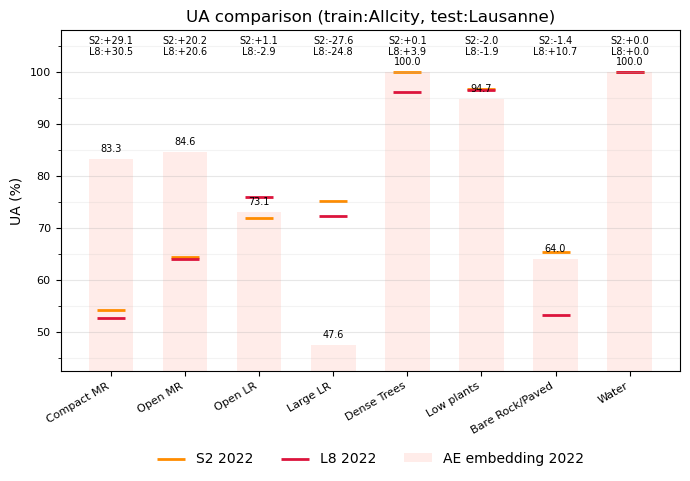

In [29]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

ref_city = test_city.capitalize()

class_names = [
    "Compact MR",
    "Open MR",
    "Open LR",
    "Large LR",
    "Dense Trees",
    "Low plants",
    "Bare Rock/Paved",
    "Water"
]

x = np.arange(len(class_names))

fig, ax = plt.subplots(figsize=(7,5))

# AE embedding bars
bars = ax.bar(
    x,
    UA,
    width=0.6,
    alpha=0.7,
    color="mistyrose",
    label="AE embedding 2022"
)

# S2 reference markers
ax.scatter(
    x,
    ref_data[ref_city]["S2"]["UA"],
    marker="_",
    s=400,
    linewidths=2,
    color="darkorange",
    label="S2 2022"
)

# L8 reference markers
ax.scatter(
    x,
    ref_data[ref_city]["L8"]["UA"],
    marker="_",
    s=400,
    linewidths=2,
    color="crimson",
    label="L8 2022"
)

# Labels and title
ax.set_title(
    f"UA comparison (train:{train_city.capitalize()}, test:{test_city.capitalize()})",
    fontsize=12
)

ax.set_ylabel("UA (%)", fontsize=10)
ax.set_ylim(60,105)
ax.yaxis.set_major_locator(ticker.MultipleLocator(10))
ax.yaxis.set_minor_locator(ticker.MultipleLocator(5))
ax.grid(which="major", axis="y", alpha=0.3)
ax.grid(which="minor", axis="y", alpha=0.15)

ax.set_xticks(x)
ax.set_xticklabels(
    class_names,
    rotation=30,
    ha="right",
    fontsize=8
)

ax.grid(axis="y", alpha=0.3)
ax.tick_params(axis="y", labelsize=8)

# Common y-range with padding
all_values = np.concatenate([
    UA,
    ref_data[ref_city]["S2"]["UA"],
    ref_data[ref_city]["L8"]["UA"]
])

ymin = max(0, np.min(all_values) - 5)
ymax = np.max(all_values) + 8
ax.set_ylim(ymin, ymax)

# Annotate AE values
for i, v in enumerate(UA):
    ax.text(
        i,
        v + 1,
        f"{v:.1f}",
        ha="center",
        va="bottom",
        fontsize=7
    )

# Annotate differences to references
for i, (ae, s2, l8) in enumerate(zip(
    UA,
    ref_data[ref_city]["S2"]["UA"],
    ref_data[ref_city]["L8"]["UA"]
)):
    ax.text(
        i,
        ymax - 1,
        f"S2:{ae-s2:+.1f}\nL8:{ae-l8:+.1f}",
        ha="center",
        va="top",
        fontsize=7
    )

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.2),
    ncol=3,
    frameon=False
)
plt.tight_layout()

plt.savefig(
    f"./images/comparison_UA_{train_city}_{test_city}_RF_"
    f"{numberOfTrees}_{variablesPerSplit}_{minLeafPopulation}.png",
    dpi=600,
    transparent=True,
    bbox_inches="tight"
)

plt.show()

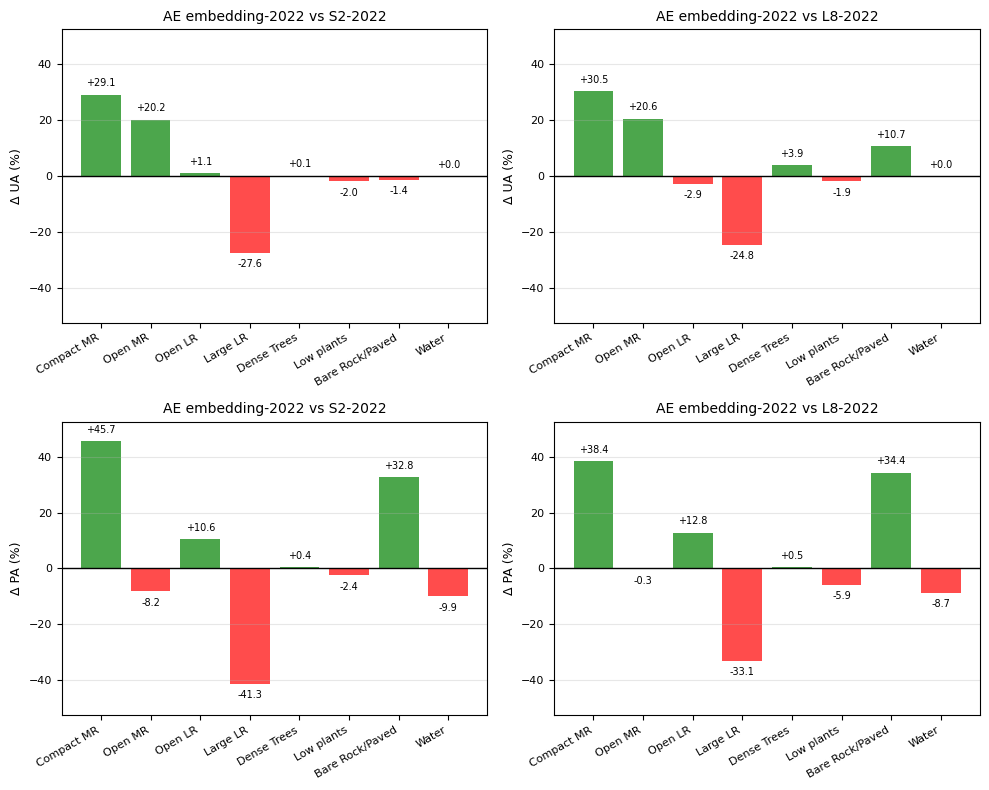

 Saved./images/validation_allcity_lausanne_RF_500_8_5.png


In [30]:

# Defines data vs reference

ref_city = test_city.capitalize()

comparisons = [
    ("AE embedding-2022 vs S2-2022", "Δ UA (%)", UA, ref_data[ref_city]["S2"]["UA"]),
    ("AE embedding-2022 vs L8-2022", "Δ UA (%)", UA, ref_data[ref_city]["L8"]["UA"]),
    ("AE embedding-2022 vs S2-2022", "Δ PA (%)", PA, ref_data[ref_city]["S2"]["PA"]),
    ("AE embedding-2022 vs L8-2022", "Δ PA (%)", PA, ref_data[ref_city]["L8"]["PA"]),
]

class_names = [
    "Compact MR",
    "Open MR",
    "Open LR",
    "Large LR",
    "Dense Trees",
    "Low plants",
    "Bare Rock/Paved",
    "Water"
]

# Compute common y-range for all subplots
max_diff = max(
    np.max(np.abs(data - ref))
    for _, _, data, ref in comparisons
)
#define pos and neg

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.ravel()

for ax, (title, ylabel, data, ref) in zip(axes, comparisons):

    diff = data - ref
    x = np.arange(len(class_names))

    colors = np.where(diff >= 0, "green", "red")

    ax.bar(x, diff, color=colors, alpha=0.7)

    # Reference level (difference = 0)
    ax.axhline(0, color="black", linewidth=1)

    ax.set_title(title, fontsize=10)
    ax.set_ylabel(ylabel, fontsize=9)

    # Same y-scale for all plots + extra space for annotations
    ax.set_ylim(-max_diff * 1.15, max_diff * 1.15)

    ax.set_xticks(x)
    ax.set_xticklabels(
        class_names,
        rotation=30,
        ha="right",
        fontsize=8
    )

    ax.tick_params(axis="y", labelsize=8)
    ax.grid(axis="y", alpha=0.3)

    # Annotate differences
    offset = max_diff * 0.05

    for i, d in enumerate(diff):
        ax.text(
            i,
            d + np.sign(d) * offset,
            f"{d:+.1f}",
            ha="center",
            va="bottom" if d >= 0 else "top",
            fontsize=7
        )

plt.tight_layout()

plt.savefig(
    f"./images/validation_{train_city}_{test_city}_RF_{numberOfTrees}_{variablesPerSplit}_{minLeafPopulation}.png", 
    dpi=600, transparent=True, bbox_inches='tight')

plt.show()
print(f" Saved./images/validation_{train_city}_{test_city}_RF_{numberOfTrees}_{variablesPerSplit}_{minLeafPopulation}.png")

### **Robustness tests**

#### **1) Feature importance**

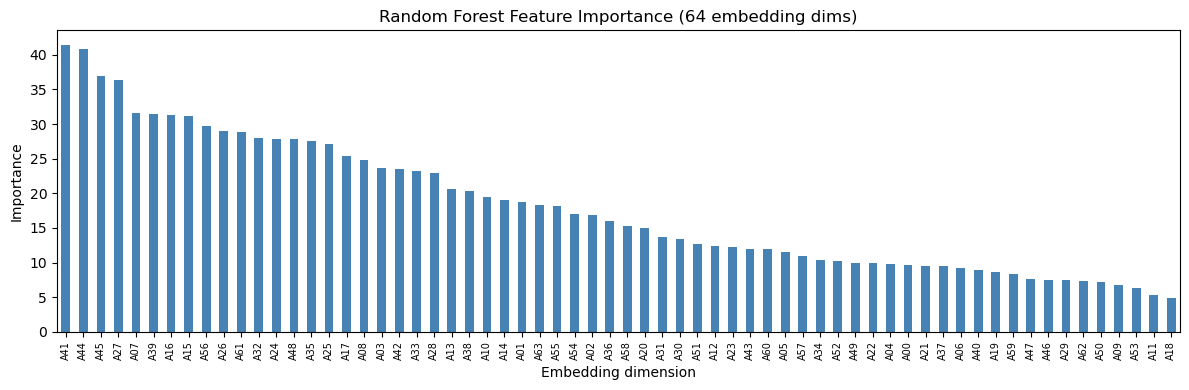

In [31]:


#!pip install seaborn
import seaborn as sns
#!pip install scipy
from scipy.stats import spearmanr

# Extract feature importances from the RF classifier

importance_dict = classifier.explain().getInfo()
importance_series = pd.Series(importance_dict['importance']).sort_values(ascending=False)


# GEE RF importance comes out as a dict {band_name: importance}


fig, ax = plt.subplots(figsize=(12, 4))
importance_series.plot(kind='bar', ax=ax, color='steelblue')
ax.set_title('Random Forest Feature Importance (64 embedding dims)')
ax.set_xlabel('Embedding dimension')
ax.set_ylabel('Importance')
ax.tick_params(axis='x', labelsize=7)
plt.tight_layout()
plt.savefig('./output/feature_importance.png', dpi=150)
plt.show()



In [32]:
# --- Trier les bandes filtrées par importance décroissante ---
importance_filtered_raw = np.array([importance_series.get(b, 0) for b in labels_filtered])
sort_idx = np.argsort(importance_filtered_raw)[::-1]

corr_sorted_imp = corr_filtered[np.ix_(sort_idx, sort_idx)]
labels_sorted_imp = [labels_filtered[i] for i in sort_idx]
importance_sorted = importance_filtered_raw[sort_idx]

# Tick labels combinés : nom de bande + importance en dessous
tick_labels = [f"{b}\n({imp:.3f})" for b, imp in zip(labels_sorted_imp, importance_sorted)]

# --- Plot ---
fig, ax = plt.subplots(figsize=(max(6, len(idx_keep)*0.5),
                                max(5, len(idx_keep)*0.45)))

im = ax.imshow(corr_sorted_imp, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')
fig.colorbar(im, ax=ax, shrink=0.6, label='Spearman r')

ax.set_xticks(range(len(tick_labels)))
ax.set_yticks(range(len(tick_labels)))
ax.set_xticklabels(tick_labels, rotation=90, fontsize=7)
ax.set_yticklabels(tick_labels, fontsize=7)

# Annoter les cellules au dessus du threshold
for i in range(len(labels_sorted_imp)):
    for j in range(len(labels_sorted_imp)):
        val = corr_sorted_imp[i, j]
        if i != j and abs(val) > threshold:
            ax.text(j, i, f'{val:.2f}', ha='center', va='center',
                    fontsize=6, fontweight='bold',
                    color='white' if abs(val) > 0.85 else 'black')

ax.set_title(f'Correlations |r| > {threshold}, triées par feature importance (décroissant)', fontsize=10)
plt.tight_layout()
plt.savefig('./output/embedding_correlation_importance.png', dpi=150, bbox_inches='tight')
plt.show()

NameError: name 'labels_filtered' is not defined

In [ ]:
### Pull embedding values to local numpy for correlation
### training is an ee.FeatureCollection — pull it
training_local = training.getInfo()
features = training_local['features']

band_names = embeddingsImage.bandNames().getInfo()
rows = []
for f in features:
    props = f['properties']
    rows.append({b: props.get(b, np.nan) for b in band_names})

df_emb = pd.DataFrame(rows)

# Spearman correlation (robust to non-linearity)
corr_matrix, _ = spearmanr(df_emb.dropna())
corr_df = pd.DataFrame(corr_matrix, index=band_names, columns=band_names)

fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(
    corr_df, 
    cmap='RdBu_r', center=0, vmin=-1, vmax=1,
    square=True, linewidths=0,
    ax=ax, cbar_kws={'shrink': 0.6}
)
ax.set_title('Spearman Cross-Correlation of 64 Embedding Dimensions')
ax.tick_params(axis='both', labelsize=6)
plt.tight_layout()
plt.savefig('./output/embedding_correlation.png', dpi=150)
plt.show()

# Flag highly correlated pairs
high_corr = []
for i in range(len(band_names)):
    for j in range(i+1, len(band_names)):
        c = corr_df.iloc[i, j]
        if abs(c) > 0.85:
            high_corr.append((band_names[i], band_names[j], round(c, 3)))
print(f"Highly correlated pairs (|r|>0.85): {len(high_corr)}")
for pair in high_corr[:10]:
    print(pair)

In [ ]:
from scipy.stats import spearmanr
from scipy.cluster.hierarchy import linkage, dendrogram, leaves_list
import numpy as np
import matplotlib.pyplot as plt

# --- Compute Spearman correlation ---
corr_matrix, _ = spearmanr(df_emb.dropna())
corr_df = pd.DataFrame(corr_matrix, index=band_names, columns=band_names)

# --- Reorder bands via hierarchical clustering ---
# Convert correlation to distance (1 - |r| so highly correlated = close)
dist = 1 - np.abs(corr_matrix)
linkage_matrix = linkage(dist, method='ward')
order = leaves_list(linkage_matrix)  # reordered indices

corr_reordered = corr_matrix[np.ix_(order, order)]
labels_reordered = [band_names[i] for i in order]

# --- Plot with matplotlib only ---
fig, ax = plt.subplots(figsize=(10, 9))

im = ax.imshow(corr_reordered, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')

# Colorbar
cbar = fig.colorbar(im, ax=ax, shrink=0.6, label='Spearman r')

# Ticks
ax.set_xticks(range(len(labels_reordered)))
ax.set_yticks(range(len(labels_reordered)))
ax.set_xticklabels(labels_reordered, rotation=90, fontsize=6)
ax.set_yticklabels(labels_reordered, fontsize=6)

ax.set_title('Embedding cross-correlation (hierarchically sorted)', fontsize=11)
plt.tight_layout()
plt.savefig('./output/embedding_correlation.png', dpi=150)
plt.show()

In [ ]:
# --- Filter to highly correlated bands only ---
threshold = 0.70
corr_abs = np.abs(corr_reordered)  # already hierarchically sorted

# Find bands that have at least one partner above threshold (excluding self)
np.fill_diagonal(corr_abs, 0)
mask = (corr_abs > threshold).any(axis=1)
idx_keep = np.where(mask)[0]

corr_filtered = corr_reordered[np.ix_(idx_keep, idx_keep)]
labels_filtered = [labels_reordered[i] for i in idx_keep]

print(f"Bands with at least one correlation > {threshold}: {len(idx_keep)} / {len(labels_reordered)}")

# --- Plot ---
fig, ax = plt.subplots(figsize=(max(6, len(idx_keep)*0.45),
                                max(5, len(idx_keep)*0.4)))

im = ax.imshow(corr_filtered, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')
fig.colorbar(im, ax=ax, shrink=0.6, label='Spearman r')

ax.set_xticks(range(len(labels_filtered)))
ax.set_yticks(range(len(labels_filtered)))
ax.set_xticklabels(labels_filtered, rotation=90, fontsize=7)
ax.set_yticklabels(labels_filtered, fontsize=7)

# Annotate cells — bold the ones above threshold
for i in range(len(labels_filtered)):
    for j in range(len(labels_filtered)):
        val = corr_filtered[i, j]
        if i != j and abs(val) > threshold:
            ax.text(j, i, f'{val:.2f}', ha='center', va='center',
                    fontsize=6, fontweight='bold',
                    color='white' if abs(val) > 0.85 else 'black')

ax.set_title(f'Embedding correlations above |r| > {threshold} (hierarchically sorted)', fontsize=10)
plt.tight_layout()
plt.savefig('./output/embedding_correlation_filtered.png', dpi=150)
plt.show()

In [ ]:
n_top = 12

# --- Top N bandes par importance, ordre inversé ---
top_bands = importance_series.sort_values(ascending=False).index[:n_top].tolist()
top_bands_rev = top_bands[::-1]
importance_top_rev = [importance_series[b] for b in top_bands_rev]

# Sous-matrice de corrélation depuis la matrice complète
corr_top_rev = corr_df.loc[top_bands_rev, top_bands_rev].values

tick_labels_top_rev = [f"{b}\n({imp:.3f})" for b, imp in zip(top_bands_rev, importance_top_rev)]

# Masquer le triangle inférieur (on garde le supérieur)
mask_tri = np.triu(np.ones((n_top, n_top), dtype=bool), k=1)
corr_top_masked = np.where(mask_tri, np.nan, corr_top_rev)

# --- Plot ---
fig, ax = plt.subplots(figsize=(8, 7))

im = ax.imshow(corr_top_masked, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')
fig.colorbar(im, ax=ax, shrink=0.7, label='Spearman r')

ax.set_xticks(range(n_top))
ax.set_yticks(range(n_top))
ax.set_xticklabels(tick_labels_top_rev, rotation=90, fontsize=8)
ax.set_yticklabels(tick_labels_top_rev, fontsize=8)

ax.set_xlabel('Embedding band (feature importance)', fontsize=9, loc='right')
#ax.set_ylabel('Embedding band (feature importance)', fontsize=9)

ax.invert_xaxis()

# Annoter triangle supérieur + diagonale
for i in range(n_top):
    for j in range(n_top):
        if j <= i:
            val = corr_top_rev[i, j]
            if i != j:
                ax.text(j, i, f'{val:.2f}', ha='center', va='center',
                        fontsize=7,
                        fontweight='bold' if abs(val) > threshold else 'normal',
                        color='white' if abs(val) > 0.85 else 'black')

#ax.set_title(f'Corrélations des {n_top} bandes les plus importantes', fontsize=11)
plt.tight_layout()
plt.savefig(f'./output/embedding_correlation_top{n_top}.png', dpi=150, bbox_inches='tight')
plt.show()

#### **3) Class distribution in training data**

In [ ]:
# --- Class distribution in training data ---
class_labels = {1:'Compact MR', 2:'Open MR', 3:'Open LR', 4:'Large LR',
                5:'Dense Trees', 6:'Low plants', 7:'Bare/Paved', 8:'Water'}

counts = train_centroids_gdf['LCZ_class'].value_counts().sort_index()
counts.index = [class_labels.get(i, i) for i in counts.index]

fig, ax = plt.subplots(figsize=(9, 4))
colors = ['#d73027' if v < counts.mean()*0.5 else '#4575b4' for v in counts.values]
counts.plot(kind='bar', ax=ax, color=colors)
ax.axhline(counts.mean(), color='black', linestyle='--', label=f'Mean ({int(counts.mean())})')
ax.set_title('Training Sample Class Distribution')
ax.set_ylabel('# centroids')
ax.set_xlabel('')
ax.tick_params(axis='x', rotation=30)
ax.legend()
plt.tight_layout()
plt.savefig('./output/class_distribution.png', dpi=150)
plt.show()

# If using allcity: also check per-city balance
if train_city == 'allcity':
    pivot = train_centroids_gdf.groupby(['city', 'LCZ_class']).size().unstack(fill_value=0)
    pivot.columns = [class_labels.get(c, c) for c in pivot.columns]
    pivot.plot(kind='bar', stacked=True, figsize=(12, 5), colormap='tab10')
    plt.title('Class distribution by city')
    plt.tight_layout()
    plt.savefig('./output/class_distribution_by_city.png', dpi=150)
    plt.show()

#### **3) Mis-classified pixels investigation**

In [ ]:
print(validation.first().getInfo())

In [ ]:
misclassified = validation.filter(ee.Filter.notEquals(leftField='classification',rightField='LCZ_class'))
print(misclassified.first().getInfo())

In [ ]:
import folium
import geopandas as gpd
from shapely.geometry import Point

class_labels = {1:'Compact MR', 2:'Open MR', 3:'Open LR', 4:'Large LR',
                5:'Dense Trees', 6:'Low plants', 7:'Bare/Paved', 8:'Water'}

# --- Pull misclassified points locally ---
# Re-run validation with geometries=True if not done yet

misclassified = validation.filter(ee.Filter.notEquals(leftField='classification',rightField='LCZ_class'))
misclassified_local = misclassified.getInfo()  # misclassified = validation.filter(neq)

rows = []
for f in misclassified_local['features']:
    props = f['properties']
    coords = f['geometry']['coordinates']
    rows.append({
        'lon': coords[0],
        'lat': coords[1],
        'true_class':      class_labels[int(props['LCZ_class'])],
        'predicted_class': class_labels[int(props['classification'])],
        'confusion':       f"{class_labels[int(props['LCZ_class'])]} → {class_labels[int(props['classification'])]}"
    })

df_mis = pd.DataFrame(rows)

# --- Color by confusion pair ---
# Assign a color per unique confusion pair for visual grouping
unique_pairs = df_mis['confusion'].unique()
cmap = plt.cm.get_cmap('tab20', len(unique_pairs))
pair_colors = {pair: '#{:02x}{:02x}{:02x}'.format(
                    int(cmap(i)[0]*255), int(cmap(i)[1]*255), int(cmap(i)[2]*255))
               for i, pair in enumerate(unique_pairs)}

# --- Build folium map ---
center = [df_mis['lat'].mean(), df_mis['lon'].mean()]
#m = folium.Map(location=center, zoom_start=13, tiles='CartoDB positron')
m = folium.Map(location=center, zoom_start=13, tiles=None)

folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Esri",
    name="Satellite",
    opacity=0.7
).add_to(m)

# Optional: add the classified raster as a tile layer via GEE
# (requires geemap's get_tile_layer_url)
map_id = classified.getMapId({'min':1,'max':8,'palette':palette})


# --- Add training polygons (semi-transparent, colored by LCZ class) ---
# Use same palette as classification
class_palette = {1:'#8B0000', 2:'#FF4500', 3:'#FFA500', 4:'#FFD700',
                 5:'#228B22', 6:'#90EE90', 7:'#A9A9A9', 8:'#1E90FF'}

train_poly_layer = folium.FeatureGroup(name='Training polygons', show=True)

for _, row in train_polygons_gdf.iterrows():
    lcz = int(row['LCZ_class'])
    color = class_palette.get(lcz, '#888888')
    
    folium.GeoJson(
        row['geometry'].__geo_interface__,
        style_function=lambda f, c=color: {
            'fillColor': c,
            'color':     c,
            'weight':    1,
            'fillOpacity': 0.25,
            'opacity':     0.6
        },
        tooltip=folium.Tooltip(
            f"<b>Training polygon</b><br>"
            f"Class: {class_labels[lcz]}<br>"
            f"City: {row.get('city', '?')}",
            sticky=True
        )
    ).add_to(train_poly_layer)

train_poly_layer.add_to(m)

# --- Add misclassified points with tooltips ---
for _, row in df_mis.iterrows():
    folium.CircleMarker(
        location=[row['lat'], row['lon']],
        radius=6,
        color=pair_colors[row['confusion']],
        fill=True,
        fill_opacity=0.85,
        tooltip=folium.Tooltip(
            f"<b>True:</b> {row['true_class']}<br>"
            f"<b>Predicted:</b> {row['predicted_class']}",
            sticky=True
        )
    ).add_to(m)

# --- Legend for confusion pairs ---
legend_html = "<div style='position:fixed;bottom:30px;left:30px;z-index:1000;" \
              "background:white;padding:10px;border-radius:6px;font-size:12px;'>"
legend_html += "<b>Confusion pairs</b><br>"
for pair, color in pair_colors.items():
    legend_html += f"<span style='color:{color}'>●</span> {pair}<br>"
legend_html += "</div>"
m.get_root().html.add_child(folium.Element(legend_html))

folium.LayerControl().add_to(m)

# Display in notebook
from folium.plugins import Fullscreen

Fullscreen(
    position="topright",
    title="Full Screen",
    title_cancel="Exit Full Screen",
    force_separate_button=True,
).add_to(m)
m

In [ ]:
# --- Class palette (indices 1-8) ---
class_labels = {1:'Compact MR', 2:'Open MR', 3:'Open LR', 4:'Large LR',
                5:'Dense Trees', 6:'Low plants', 7:'Bare/Paved', 8:'Water'}
palette = ['#8B0000','#FF4500','#FFA500','#FFD700','#228B22','#90EE90','#A9A9A9','#1E90FF']

# --- Flag misclassified points ---
misclassified = validation.filter(ee.Filter.neq('classification', 'LCZ_class'))
correct        = validation.filter(ee.Filter.eq('classification',  'LCZ_class'))

# --- Specific confusion pairs you care about ---
water_as_paved = validation.filter(
    ee.Filter.And(ee.Filter.eq('LCZ_class', 8),
                  ee.Filter.eq('classification', 7))
)
paved_as_water = validation.filter(
    ee.Filter.And(ee.Filter.eq('LCZ_class', 7),
                  ee.Filter.eq('classification', 8))
)

# --- Map ---
Map = geemap.Map()
Map.centerObject(test_centroids, zoom=12)

#Map.addLayer(classified,
#             {'min':1, 'max':8, 'palette': palette},
#             'LCZ classified map')

Map.addLayer(correct,       {'color': 'white'},   'Correct predictions')
Map.addLayer(misclassified, {'color': 'red'},      'All misclassified')
Map.addLayer(water_as_paved,{'color': 'magenta'},  'Water predicted as Bare/Paved')
Map.addLayer(paved_as_water,{'color': 'cyan'},     'Bare/Paved predicted as Water')

Map.add_legend(title='LCZ Classes',
               legend_dict={**{v: palette[k-1] for k,v in class_labels.items()},
                            'Correct': '#ffffff',
                            'Misclassified': '#ff0000',
                            'Water→Paved': '#ff00ff',
                            'Paved→Water': '#00ffff'})
Map

In [ ]:
# Pull to local dataframe
val_local = validation.getInfo()
rows = [f['properties'] for f in val_local['features']]
rows = [f['properties'] for f in val_local['features']]
df_val = pd.DataFrame(rows)
df_val['correct'] = df_val['classification'] == df_val['LCZ_class']
df_val['geometry'] = [f['geometry']['coordinates'] for f in val_local['features']]
df_val['lon'] = df_val['geometry'].apply(lambda c: c[0])
df_val['lat'] = df_val['geometry'].apply(lambda c: c[1])

In [ ]:
#!pip install scikit-learn
from sklearn.metrics import confusion_matrix, classification_report

print(classification_report(
    df_val['LCZ_class'],
    df_val['classification'],
    target_names=[class_labels[i] for i in sorted(class_labels)],
    labels=sorted(class_labels.keys())
))

# Visual: per-class recall bar chart
from sklearn.metrics import recall_score
recalls = recall_score(df_val['LCZ_class'], df_val['classification'],
                       labels=sorted(class_labels.keys()), average=None)

fig, ax = plt.subplots(figsize=(9, 4))
colors = ['#d73027' if r < 0.6 else '#4575b4' for r in recalls]
ax.bar([class_labels[i] for i in sorted(class_labels)], recalls, color=colors)
ax.axhline(0.6, color='black', linestyle='--', label='0.6 threshold')
ax.set_ylabel('Recall')
ax.set_title(f'Per-class recall — test city: {test_city}')
ax.set_ylim(0, 1)
ax.tick_params(axis='x', rotation=30)
ax.legend()
plt.tight_layout()
plt.savefig(f'./output/recall_{test_city}.png', dpi=150)
plt.show()

In [ ]:
from scipy.spatial.distance import cdist

coords = df_val[['lon','lat']].values
errors = (~df_val['correct']).astype(float).values  # 1=error, 0=correct

# Build inverse-distance spatial weights (threshold at ~500m in degrees ≈ 0.005)
dist_matrix = cdist(coords, coords)
np.fill_diagonal(dist_matrix, np.inf)
threshold = 0.001  # ~500m — adjust based on your point density
W = np.where(dist_matrix < threshold, 1.0 / dist_matrix, 0)
W /= W.sum(axis=1, keepdims=True)  # row-normalize

# Moran's I
n   = len(errors)
z   = errors - errors.mean()
num = n * (W * np.outer(z, z)).sum()
den = (W.sum()) * (z**2).sum()
morans_i = num / den

print(f"Moran's I (errors): {morans_i:.4f}")
print("  > 0 → errors spatially clustered")
print("  ≈ 0 → errors spatially random")
print("  < 0 → errors spatially dispersed")

# Repeat for specific confusion pair (water→paved)
df_val['water_as_paved'] = ((df_val['LCZ_class']==8) & (df_val['classification']==7)).astype(float)
z2  = df_val['water_as_paved'].values - df_val['water_as_paved'].mean()
num2 = n * (W * np.outer(z2, z2)).sum()
den2 = (W.sum()) * (z2**2).sum()
print(f"Moran's I (water→paved specifically): {num2/den2:.4f}")

In [ ]:
# Pull embedding values at test points (already sampled in validation)
# Need to re-sample with all band properties kept
validation_emb = embeddingsImage.sampleRegions(
    collection=test_centroids,
    properties=['LCZ_class'],
    scale=10
)
val_emb_local = validation_emb.getInfo()
rows_emb = [f['properties'] for f in val_emb_local['features']]
df_emb_test = pd.DataFrame(rows_emb)

band_names = embeddingsImage.bandNames().getInfo()

# Compute per-class centroid in embedding space
class_centroids_emb = df_emb_test.groupby('LCZ_class')[band_names].mean()

# Pairwise Euclidean distance between class centroids
from scipy.spatial.distance import cdist
emb_dist = pd.DataFrame(
    cdist(class_centroids_emb.values, class_centroids_emb.values),
    index=[class_labels[i] for i in class_centroids_emb.index],
    columns=[class_labels[i] for i in class_centroids_emb.index]
)

# Plot
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(emb_dist.values, cmap='viridis_r', aspect='auto')
fig.colorbar(im, ax=ax, label='Euclidean distance in embedding space')
ax.set_xticks(range(len(emb_dist)))
ax.set_yticks(range(len(emb_dist)))
ax.set_xticklabels(emb_dist.columns, rotation=45, ha='right', fontsize=8)
ax.set_yticklabels(emb_dist.index, fontsize=8)
ax.set_title('Inter-class distance in 64-dim embedding space')

# Annotate cells
for i in range(len(emb_dist)):
    for j in range(len(emb_dist)):
        ax.text(j, i, f'{emb_dist.values[i,j]:.1f}',
                ha='center', va='center', fontsize=7,
                color='white' if emb_dist.values[i,j] < emb_dist.values.max()*0.5 else 'black')
plt.tight_layout()
plt.savefig('./output/embedding_interclass_distance.png', dpi=150)
plt.show()

# Print the closest pairs — those are your structurally hard confusions
emb_dist_flat = emb_dist.copy()
np.fill_diagonal(emb_dist_flat.values, np.inf)
print("\nClosest class pairs in embedding space:")
for _ in range(5):
    idx = np.unravel_index(emb_dist_flat.values.argmin(), emb_dist_flat.shape)
    print(f"  {emb_dist_flat.index[idx[0]]} ↔ {emb_dist_flat.columns[idx[1]]}: "
          f"{emb_dist_flat.values[idx[0], idx[1]]:.3f}")
    emb_dist_flat.values[idx[0], idx[1]] = np.inf
    emb_dist_flat.values[idx[1], idx[0]] = np.inf

### Visualize classified map

In [ ]:
palette = [
    "#7A2A12",  # Compact MR
    "#DE6321",  # Open MR
    "#EAC89E",  # Open LR
    "#CFC9AE",  # Large LR
    "#5A772C",  # Dense Trees
    "#A2C766",  # Low plants
    "#4A442B",  # Bare Rock/Paved
    "#89C9E8"   # Water
]

#classified_vis = classified.remap(
#    [2, 5, 6, 8, 11, 14, 15, 17],
#    [1, 2, 3, 4, 5, 6, 7, 8]
#)

Map.addLayer(
  classified.clip(roi),
  {"min": 1, "max": 8, "palette": palette},
  'Classified Satellite Embeddings Image');


#Map.add_basemap('SATELLITE')
Map

#print(train_centroids_gdf['macroclass_id'].value_counts())
#print(train_centroids.geometry().bounds().getInfo())
#print(roi.bounds().getInfo())


#Map.addLayer(train_centroids, {}, 'train points')
#Map.addLayer(embeddingsImage, {}, 'embeddings')
#Map

#print(training.first().getInfo())

In [ ]:
## Export classified map 

# Convert classes -> RGB image
classified_rgb = classified.visualize(
    min=1,
    max=8,
    palette=palette
)

# Export GeoTIFF
out_dir = "./images/"
geemap.ee_export_image(
    classified_rgb.clip(roi),
    filename=out_dir+f"classified_map_RGB_{train_city}_{test_city}_RF_{numberOfTrees}_{variablesPerSplit}_{minLeafPopulation}.tif",
    scale=70,
    region=roi,
    file_per_band=False
)

# Export training points/polygons
geemap.ee_to_geojson(
    train_centroids,
    filename=out_dir+'training_points_v4.geojson'
)
Map

